# Slices

Slices (`&SLCF`) are the most common FDS output: a quantity on a plane (2D) or in a box (3D),
written at every output time. This notebook shows how to find a slice, read its data,
mask obstructions and merge the slices of several meshes into one array.

It uses two cases in this folder; run FDS on them first:

- `fds_steckler/input_steckler.fds`: the Steckler room, one mesh, a temperature slice
  through the door (`PBY=0`)
- `fds_multimesh/multimesh.fds`: four meshes with an obstruction, two horizontal
  temperature slices

In [1]:
import matplotlib.pyplot as plt
import numpy as np

import fdsreader as fds

## Load a simulation and find a slice

`Simulation` takes the directory with the `.smv` file. `sim.slices` holds every slice of the
simulation; filter it by quantity and pick the one closest to a position.

In [2]:
sim = fds.Simulation("./fds_steckler")
sim.slices

SliceCollection([Slice([2D] quantity=Quantity('TEMPERATURE'), cell_centered=False, extent=Extent([0.00, 3.60] x [0.00, 0.00] x [0.00, 2.13]), extent_dirs=('x', 'z'), orientation=2),
Slice([2D] quantity=Quantity('TEMPERATURE'), cell_centered=True, extent=Extent([0.00, 3.60] x [0.10, 0.10] x [0.00, 2.13]), extent_dirs=('x', 'z'), orientation=2)])

In [3]:
slc = sim.slices.filter_by_quantity("TEMPERATURE").get_nearest(y=0)
print(slc.quantity.name, slc.quantity.unit)
print("extent:", slc.extent)
print("time steps:", slc.n_t, "from", slc.times[0], "to", slc.times[-1], "s")

TEMPERATURE C
extent: Extent([0.00, 3.60] x [0.00, 0.00] x [0.00, 2.13])
time steps: 101 from 0.0 to 100.0 s


Slices with an `ID` on the `&SLCF` line can also be looked up with
`sim.slices.get_by_id("...")`.

## Data of one mesh

A slice is split into one *subslice* per mesh it cuts through. Its `data` is a NumPy array
with time as the first axis, followed by the two in-plane directions (here x and z).

In [4]:
mesh = sim.meshes[0]
subslice = slc[mesh]
coords = subslice.get_coordinates()
print("data:", subslice.data.shape, " x:", coords["x"].shape, " z:", coords["z"].shape)

data: (101, 37, 23)  x: (37,)  z: (23,)


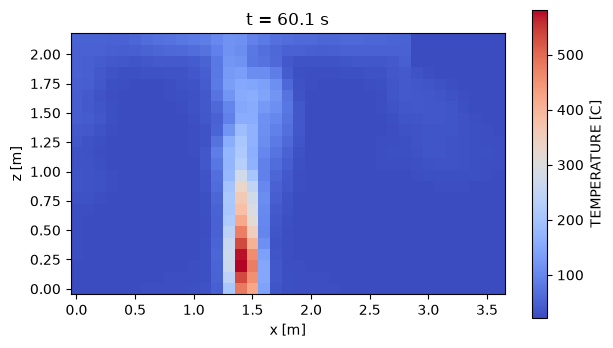

In [5]:
t = slc.get_nearest_timestep(60.0)

fig, ax = plt.subplots(figsize=(7, 4))
pcm = ax.pcolormesh(coords["x"], coords["z"], subslice.data[t].T, shading="nearest", cmap="coolwarm")
fig.colorbar(pcm, label=f"{slc.quantity.name} [{slc.quantity.unit}]")
ax.set(xlabel="x [m]", ylabel="z [m]", title=f"t = {slc.times[t]:.1f} s", aspect="equal");

## Mask obstructions

FDS writes a placeholder into the cells inside an obstruction, and into the nodes inside it;
the nodes on its faces get values of the gas next to it. `Mesh.get_obstruction_mask_slice`
returns a mask that is `False` where FDS wrote the placeholder.

The wall with the door is one cell thick, so the node-based slice above has no nodes inside
it: FDS writes the gas values of both sides on its faces. The cell-centred slice in the same
plane (`ID='door_cc'`) does have the wall's cells; replacing them with NaN leaves the wall
above the door blank.

blocked cells in the cell-centred slice: 3
blocked nodes in the node-based slice: 0


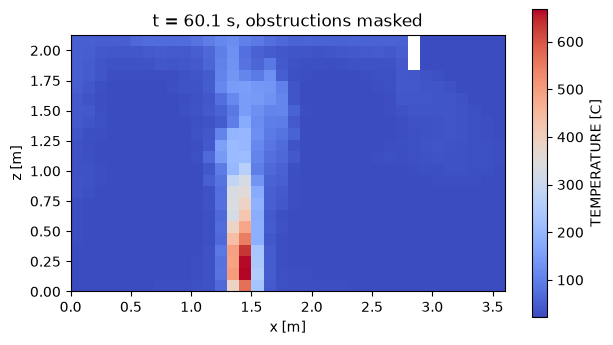

In [6]:
slc_cc = sim.slices.get_by_id("door_cc")
sub_cc = slc_cc[mesh]
coords_cc = sub_cc.get_coordinates()
t_cc = slc_cc.get_nearest_timestep(60.0)
mask = mesh.get_obstruction_mask_slice(sub_cc)
masked = np.where(np.squeeze(mask)[t_cc], sub_cc.data[t_cc], np.nan)
print("blocked cells in the cell-centred slice:", int((~mask[t_cc]).sum()))
print("blocked nodes in the node-based slice:", int((~mesh.get_obstruction_mask_slice(subslice)[t]).sum()))

fig, ax = plt.subplots(figsize=(7, 4))
pcm = ax.pcolormesh(coords_cc["x"], coords_cc["z"], masked.T, shading="nearest", cmap="coolwarm")
fig.colorbar(pcm, label=f"{slc_cc.quantity.name} [{slc_cc.quantity.unit}]")
ax.set(xlabel="x [m]", ylabel="z [m]", title=f"t = {slc_cc.times[t_cc]:.1f} s, obstructions masked", aspect="equal");

## Time series at a point

Index the data at the grid point closest to a position to follow it over time, here in the
plume above the burner and in the upper part of the door.

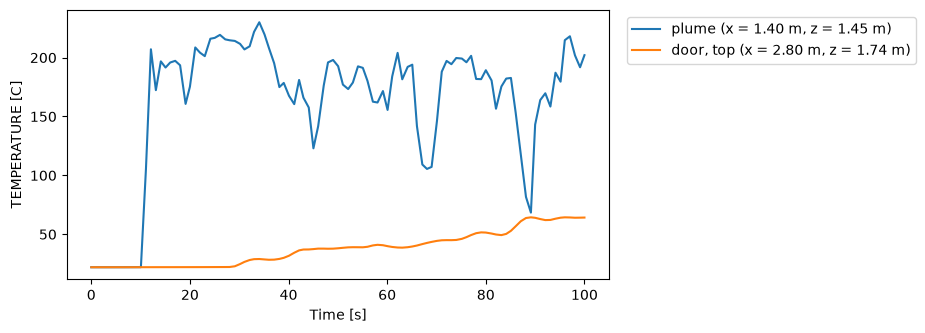

In [7]:
data = slc.to_global()
coords = slc.get_coordinates()

fig, ax = plt.subplots(figsize=(7, 3.5))
for x, z, label in [(1.4, 1.5, "plume"), (2.85, 1.7, "door, top")]:
    ix = np.argmin(np.abs(coords["x"] - x))
    iz = np.argmin(np.abs(coords["z"] - z))
    ax.plot(slc.times, data[:, ix, iz], label=f"{label} (x = {coords['x'][ix]:.2f} m, z = {coords['z'][iz]:.2f} m)")
ax.set(xlabel="Time [s]", ylabel=f"{slc.quantity.name} [{slc.quantity.unit}]")
ax.legend(loc="upper left", bbox_to_anchor=(1.02, 1));

## Several meshes

In a simulation with several meshes, `to_global` merges the subslices into one array on a
common grid. With `masked=True` obstructions are filled with `fill`, and
`return_coordinates=True` also returns the grid.

In [8]:
sim_mm = fds.Simulation("./fds_multimesh")
print(len(sim_mm.meshes), "meshes")
slc_mm = sim_mm.slices.filter_by_quantity("TEMPERATURE").get_nearest(z=0.5)
data_mm, coords_mm = slc_mm.to_global(masked=True, fill=np.nan, return_coordinates=True)
print("global data:", data_mm.shape)

4 meshes
global data: (13, 31, 31)


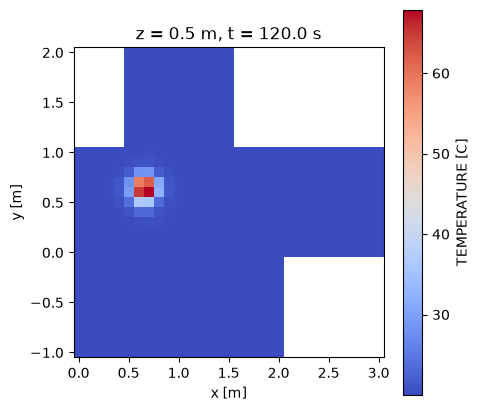

In [9]:
fig, ax = plt.subplots(figsize=(5, 5))
pcm = ax.pcolormesh(coords_mm["x"], coords_mm["y"], data_mm[-1].T, shading="nearest", cmap="coolwarm")
fig.colorbar(pcm, label=f"{slc_mm.quantity.name} [{slc_mm.quantity.unit}]")
ax.set(xlabel="x [m]", ylabel="y [m]", title=f"z = 0.5 m, t = {slc_mm.times[-1]:.1f} s", aspect="equal");

The four meshes do not fill the whole bounding box, so the areas outside them stay blank.
The hot spot is the plume above the burner.

For more on the data structure and all methods see the
[API reference](https://fdsreader.readthedocs.io/en/latest/api/slcf.html).